# Major-outage EDA (training data only)

Approved task: for utility crew staging, predict whether a county will have **at least 5,000 customers out at the same time** in the 72 hours after the first storm-family NWS watch or warning issued for it (decisions D-17 to D-24). Non-major labels need `cov90` coverage (260 of 288 runs, no gap over 1 hour); windows already major at the prediction time are reported separately. Models are fit and evaluated on **covered windows**, where both outcomes needed that coverage. Definitions: `docs/project_specification.md`, `docs/feature_dictionary.md`, `docs/dataset_card.md`.

Everything below uses **2014-11 to 2023 training rows** from `pipeline/13_build_major_outage_dataset.py`. This notebook is the repository endpoint; the teammate will build the baseline. Prior 2024 model development is disclosed, but its code and results have been removed. No 2025 outcome is read. Every chart is followed by the table it draws.

In [1]:
from pathlib import Path
import json
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'AGENTS.md').exists())
import sys
sys.path.insert(0, str(ROOT))
from pipeline.paths import MODEL_INPUT
DATA = MODEL_INPUT / 'southeast_v1'
REPORTS = ROOT / 'reports'
manifest = json.loads((DATA / 'manifest.json').read_text())
con = duckdb.connect()
alert = con.execute('SELECT * FROM read_parquet(?)', [str(DATA / 'alert_train.parquet')]).df()
onset = con.execute('SELECT * FROM read_parquet(?)', [str(DATA / 'onset_train.parquet')]).df()
for frame in (alert, onset):
    frame['year'] = pd.to_datetime(frame.t0).dt.year
    frame['labelled'] = frame.y_major.notna()
pd.set_option('display.max_columns', 30)

# Reference palette from the dataviz skill: light surface, fixed slot order, text in ink tokens.
INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
SLOTS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'font.size': 10, 'figure.dpi': 110})

def style(ax, title, xlabel='', ylabel=''):
    ax.set_title(title, loc='left', color=INK, fontsize=11, fontweight='bold')
    ax.set_xlabel(xlabel, color=INK2); ax.set_ylabel(ylabel, color=INK2)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(True, axis='y', color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for side in ('top', 'right'): ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'): ax.spines[side].set_color(AXIS)
print(f"training alert rows {len(alert):,}; labelled {alert.labelled.sum():,}; onset rows {len(onset):,}; labelled {onset.labelled.sum():,}")

training alert rows 75,594; labelled 4,607; onset rows 33,462; labelled 7,896


C:\Users\chris\AppData\Local\Temp\ipykernel_30232\518748636.py:17: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  alert = con.execute('SELECT * FROM read_parquet(?)', [str(DATA / 'alert_train.parquet')]).df()
C:\Users\chris\AppData\Local\Temp\ipykernel_30232\518748636.py:18: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  onset = con.execute('SELECT * FROM read_parquet(?)', [str(DATA / 'onset_train.parquet')]).df()


## 1. Label prevalence and availability by year

Most alert windows are never covered: EAGLE-I omits zero-outage rows, so three days of near-continuous reporting are needed. Coverage rises as EAGLE-I grows. Crossing-only majors outside covered windows are excluded from fitting and evaluation.

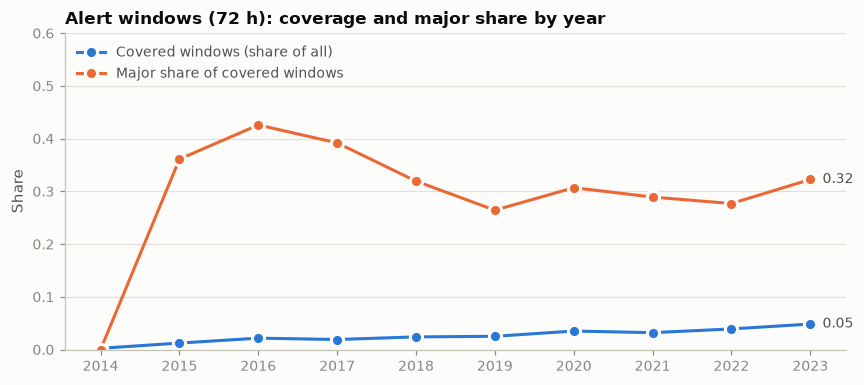

,windows,labelled,covered,covered_major,ongoing,covered_share,major_share_of_covered
year,,,,,,,
2014,839,8,2,0,0,0.002,0.0
2015,8780,241,108,39,3,0.012,0.361
2016,7484,417,162,69,31,0.022,0.426
2017,7768,448,148,58,27,0.019,0.392
2018,8994,527,216,69,41,0.024,0.319
2019,7681,390,193,51,5,0.025,0.264
2020,8999,711,316,97,12,0.035,0.307
2021,7769,415,249,72,8,0.032,0.289
2022,8311,640,325,90,19,0.039,0.277


In [2]:
alert['covered'] = alert.covered_window.fillna(False).astype(bool)
alert['covered_major'] = alert.covered & (alert.y_major == 1)
by_year = alert.groupby('year').agg(windows=('opportunity_id', 'size'), labelled=('labelled', 'sum'), covered=('covered', 'sum'),
                                    covered_major=('covered_major', 'sum'), ongoing=('label', lambda s: (s == 'ongoing').sum()))
by_year['covered_share'] = by_year.covered / by_year.windows
by_year['major_share_of_covered'] = by_year.covered_major / by_year.covered
fig, ax = plt.subplots(figsize=(8, 3.6))
for col, color, name in [('covered_share', SLOTS[0], 'Covered windows (share of all)'), ('major_share_of_covered', SLOTS[1], 'Major share of covered windows')]:
    ax.plot(by_year.index, by_year[col], color=color, linewidth=2, marker='o', markersize=8, markeredgecolor=SURFACE, markeredgewidth=2, label=name)
    ax.annotate(f'{by_year[col].iloc[-1]:.2f}', (by_year.index[-1], by_year[col].iloc[-1]), xytext=(8, 0), textcoords='offset points', va='center', color=INK2, fontsize=9)
ax.set_ylim(0, 0.6); ax.set_xticks(by_year.index)
style(ax, 'Alert windows (72 h): coverage and major share by year', '', 'Share')
ax.legend(frameon=False, fontsize=9, labelcolor=INK2, loc='upper left'); fig.tight_layout(); plt.show()
display(by_year.round(3))

## 2. Who gets labelled: county size

Selection is strong. Large counties have persistent small outages, so every run produces a row and coverage holds. Small rural counties are almost never covered. Results apply to covered windows only.

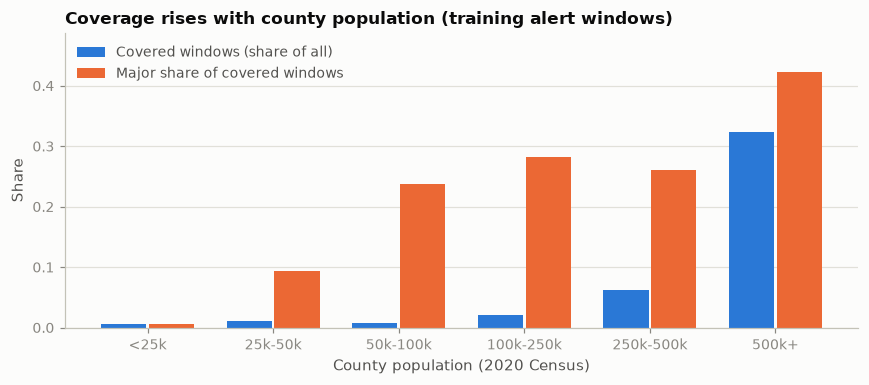

,windows,covered,covered_major,covered_share,major_share_of_covered
size_bin,,,,,
1: <25k,25549,156,1,0.006,0.006
2: 25k-50k,16999,180,17,0.011,0.094
3: 50k-100k,13184,101,24,0.008,0.238
4: 100k-250k,11295,237,67,0.021,0.283
5: 250k-500k,4955,310,81,0.063,0.261
6: 500k+,3612,1169,495,0.324,0.423


In [3]:
order = sorted(alert.size_bin.unique())
size = alert.groupby('size_bin').agg(windows=('opportunity_id', 'size'), covered=('covered', 'sum'), covered_major=('covered_major', 'sum')).reindex(order)
size['covered_share'] = size.covered / size.windows
size['major_share_of_covered'] = size.covered_major / size.covered
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(order)); w = 0.36
for i, (col, name) in enumerate([('covered_share', 'Covered windows (share of all)'), ('major_share_of_covered', 'Major share of covered windows')]):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), size[col], width=w, color=SLOTS[i], label=name)
ax.set_xticks(x, [o.split(': ')[1] for o in order]); ax.set_ylim(0, max(size[['covered_share', 'major_share_of_covered']].max()) * 1.15)
style(ax, 'Coverage rises with county population (training alert windows)', 'County population (2020 Census)', 'Share')
ax.legend(frameon=False, fontsize=9, labelcolor=INK2, loc='upper left'); fig.tight_layout(); plt.show()
display(size.round(3))

## 3. Severity distribution

Severity is the observed peak in covered windows (provisional population, decision O-7). The distribution is heavily right-skewed.

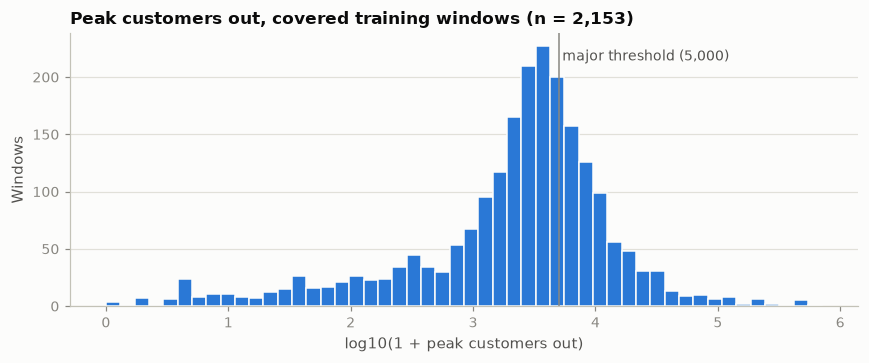

,peak_customers
count,2153.0
mean,8561.0
std,33273.0
min,0.0
25%,1144.0
50%,3105.0
75%,6299.0
90%,13210.0
99%,121994.0
max,712571.0


In [4]:
sev = alert.loc[alert.covered, 'peak_customers']
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(np.log10(1 + sev), bins=50, color=SLOTS[0], edgecolor=SURFACE, linewidth=1)
ax.axvline(np.log10(5001), color=MUTED, linewidth=1)
ax.text(np.log10(5001) + 0.03, ax.get_ylim()[1] * 0.9, 'major threshold (5,000)', color=INK2, fontsize=9)
style(ax, f'Peak customers out, covered training windows (n = {len(sev):,})', 'log10(1 + peak customers out)', 'Windows')
fig.tight_layout(); plt.show()
display(sev.describe(percentiles=[.25, .5, .75, .9, .99]).round(0).to_frame('peak_customers'))

## 4. Missing feature values

Missing values are kept. The teammate will choose missing-value handling when defining the baseline. `log_mcc_valid` is missing wherever the modeled customer count failed validation, including all of North Carolina. EAGLE-I values before t0 are missing when the county had no row.

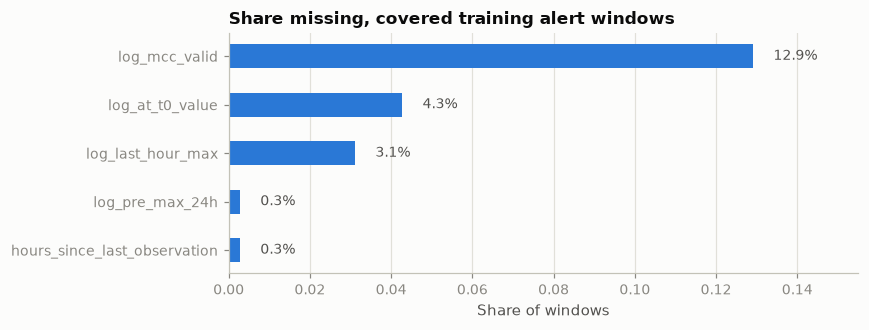

,missing_share
log_mcc_valid,0.129
log_at_t0_value,0.043
log_last_hour_max,0.031
log_pre_max_24h,0.003
hours_since_last_observation,0.003


In [5]:
feats = manifest['features']['alert']
lab = alert[alert.covered]
missing = lab[feats].isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(8, 0.42 * len(missing) + 1))
ax.barh(missing.index[::-1], missing.values[::-1], height=0.5, color=SLOTS[0])
for i, v in enumerate(missing.values[::-1]):
    ax.text(v + 0.005, i, f'{v:.1%}', va='center', color=INK2, fontsize=9)
ax.set_xlim(0, missing.max() * 1.2); style(ax, 'Share missing, covered training alert windows', 'Share of windows', '')
ax.grid(True, axis='x', color=GRID, linewidth=0.8); ax.grid(False, axis='y'); fig.tight_layout(); plt.show()
display(missing.round(3).to_frame('missing_share'))

## 5. Representation: states and alert families

Convective and flood alerts dominate covered windows; tropical alerts are few but carry high major shares; wind and winter alerts barely appear.

In [6]:
rep = lab.groupby(['state']).agg(labelled=('opportunity_id', 'size'), major=('y_major', 'sum'))
rep['major_share'] = rep.major / rep.labelled
fam = lab.groupby('primary_family').agg(labelled=('opportunity_id', 'size'), major=('y_major', 'sum'))
fam['major_share'] = fam.major / fam.labelled
display(rep.round(3)); display(fam.sort_values('labelled', ascending=False).round(3))

,labelled,major,major_share
state,,,
AL,181,67,0.37
FL,884,289,0.327
GA,394,112,0.284
NC,207,74,0.357
SC,169,23,0.136
TN,318,120,0.377


,labelled,major,major_share
primary_family,,,
convective,1392,486,0.349
flood,613,131,0.214
tropical,77,50,0.649
winter,40,8,0.2
coastal,23,5,0.217
wind,8,5,0.625


## 6. Outages already underway at t0

Windows already at 5,000 or more customers out at the last available EAGLE-I run are labelled `ongoing` and excluded from the primary target (decision D-20). For most windows the last run before t0 has no row, so the t0 state is not observed.

In [7]:
pre = alert.groupby('year').agg(windows=('opportunity_id', 'size'), ongoing=('label', lambda s: (s == 'ongoing').sum()),
                                 row_at_last_run=('at_t0_row_present', 'mean'))
display(pre.round(3))

,windows,ongoing,row_at_last_run
year,,,
2014,839,0,0.168
2015,8780,3,0.197
2016,7484,31,0.239
2017,7768,27,0.263
2018,8994,41,0.341
2019,7681,5,0.362
2020,8999,12,0.365
2021,7769,8,0.364
2022,8311,19,0.385


## 7. Timing of the first major crossing after an alert

Evidence for decision D-21, from the 24-hour feasibility audit windows in stage 12: among first major crossings within 96 hours of an alert, only 19% (tropical) and 23% (winter) fall inside 24 hours, against 97% inside 72 hours. Onset rows mostly cross within 24 hours, so they keep the 24-hour window.

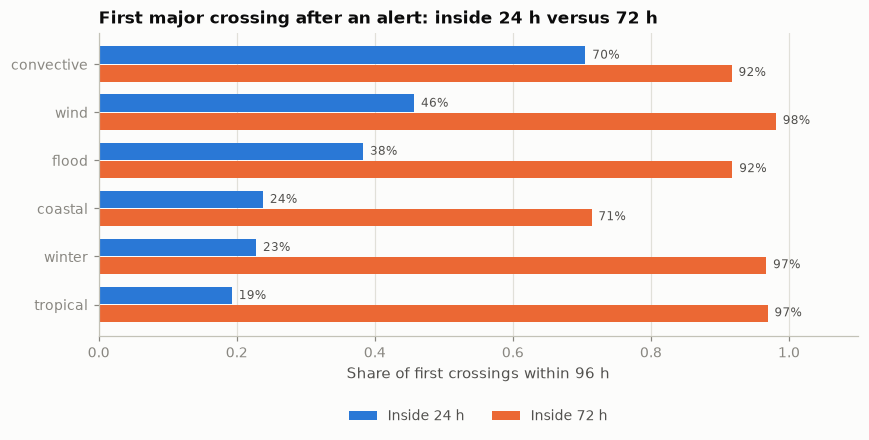

,design,trigger_family,windows_crossing_within_96h,share_within_24h,share_within_48h,share_within_72h,median_hours_to_first_crossing
0,alert,convective,2676,0.705,0.833,0.917,5.4
1,alert,flood,1165,0.383,0.718,0.918,34.6
2,alert,tropical,610,0.193,0.556,0.969,45.3
3,alert,winter,241,0.228,0.622,0.967,41.5
4,alert,wind,105,0.457,0.810,0.981,26.0
5,alert,coastal,42,0.238,0.548,0.714,41.5
6,onset,convective_wind,1577,0.827,0.903,0.955,0.8
7,onset,tropical,538,0.929,0.980,0.996,5.3
8,onset,rain_flood,328,0.649,0.814,0.933,10.0
9,onset,winter,233,0.811,0.936,0.987,10.3


In [8]:
timing = pd.read_csv(REPORTS / 'forecast_feasibility' / 'outcome_window_timing.csv')
t = timing[timing.design == 'alert'].set_index('trigger_family').sort_values('share_within_24h')
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(t)); h = 0.36
ax.barh(y + h / 2 + 0.01, t.share_within_24h, height=h, color=SLOTS[0], label='Inside 24 h')
ax.barh(y - h / 2 - 0.01, t.share_within_72h, height=h, color=SLOTS[1], label='Inside 72 h')
for i, (a, b) in enumerate(zip(t.share_within_24h, t.share_within_72h)):
    ax.text(a + 0.01, i + h / 2, f'{a:.0%}', va='center', color=INK2, fontsize=8)
    ax.text(b + 0.01, i - h / 2, f'{b:.0%}', va='center', color=INK2, fontsize=8)
ax.set_yticks(y, t.index); ax.set_xlim(0, 1.1)
style(ax, 'First major crossing after an alert: inside 24 h versus 72 h', 'Share of first crossings within 96 h', '')
ax.legend(frameon=False, fontsize=9, labelcolor=INK2, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.grid(True, axis='x', color=GRID, linewidth=0.8); ax.grid(False, axis='y'); fig.tight_layout(); plt.show()
display(timing)

## 8. Differences across training years

Major shares among labelled windows vary by year with the storm mix (for example the 2017-2018 hurricanes) and with EAGLE-I coverage. Rolling chronological checks would show how stable a model is across these regimes.

In [9]:
yr_state = lab.pivot_table(index='year', columns='state', values='y_major', aggfunc='mean')
display(yr_state.round(2))
display(lab.pivot_table(index='year', columns='primary_family', values='y_major', aggfunc='size', fill_value=0))
con.close()

state,AL,FL,GA,NC,SC,TN
year,,,,,,
2014,<NA>,0.0,<NA>,0.0,<NA>,<NA>
2015,<NA>,0.38,0.31,0.5,0.0,0.46
2016,<NA>,0.5,0.64,0.31,0.0,0.53
2017,<NA>,0.44,0.43,0.17,0.2,0.5
2018,0.41,0.29,0.5,0.28,0.28,0.31
2019,0.25,0.22,0.33,0.33,0.07,0.56
2020,0.36,0.28,0.24,0.56,0.25,0.37
2021,0.31,0.37,0.24,0.47,0.09,0.19
2022,0.33,0.31,0.19,0.52,0.04,0.29


primary_family,coastal,convective,flood,tropical,wind,winter
year,,,,,,
2014,0,2,0,0,0,0
2015,0,61,41,0,0,6
2016,6,93,50,11,1,1
2017,0,74,56,13,0,5
2018,2,118,89,3,0,4
2019,0,137,43,11,1,1
2020,2,202,94,15,2,1
2021,1,136,94,4,1,13
2022,6,215,78,15,3,8
